In [ ]:
# 1. IMPORT LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

In [ ]:
# 2. LOAD DATASET
from google.colab import files
uploaded = files.upload()

Saving Mall_Customers.csv to Mall_Customers (1).csv


In [ ]:
df = pd.read_csv('Mall_Customers.csv')
print(df.head())

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


In [ ]:
#3. DATA CHECKING & PREPARATION
print("\n📋 Informasi Dataset:")
print(df.info())


📋 Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None


In [ ]:
print("\n🔍 Mengecek Missing Value:")
print(df.isnull().sum())


🔍 Mengecek Missing Value:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [ ]:
# Menghapus kolom yang tidak relevan (CustomerID)
# df = df.drop('CustomerID', axis=1) # This line is commented out because the column has already been dropped.

In [ ]:
# Mengubah Gender menjadi numerik
df['Gender'] = df['Gender'].map({'Male': 0, 'Female': 1})

In [ ]:
#4. EXPLORATORY DATA ANALYSIS (EDA)
print("\n📊 Statistik Deskriptif:")
print(df.describe())



📊 Statistik Deskriptif:
       CustomerID      Gender         Age  Annual Income (k$)  \
count  200.000000  200.000000  200.000000          200.000000   
mean   100.500000    0.560000   38.850000           60.560000   
std     57.879185    0.497633   13.969007           26.264721   
min      1.000000    0.000000   18.000000           15.000000   
25%     50.750000    0.000000   28.750000           41.500000   
50%    100.500000    1.000000   36.000000           61.500000   
75%    150.250000    1.000000   49.000000           78.000000   
max    200.000000    1.000000   70.000000          137.000000   

       Spending Score (1-100)  
count              200.000000  
mean                50.200000  
std                 25.823522  
min                  1.000000  
25%                 34.750000  
50%                 50.000000  
75%                 73.000000  
max                 99.000000  


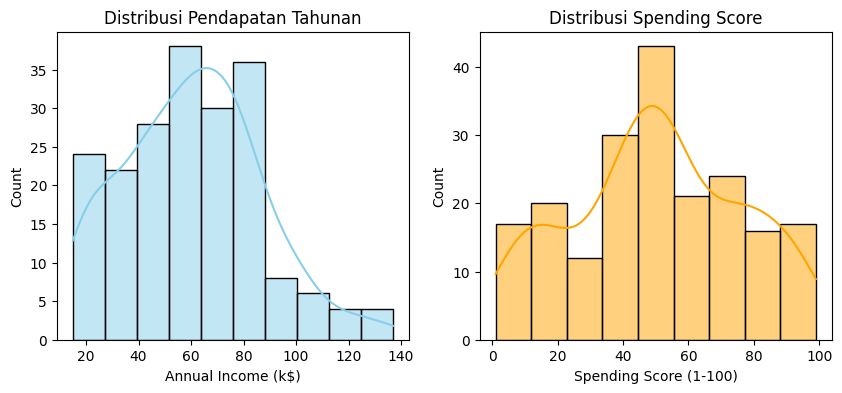

In [ ]:
# Visualisasi distribusi fitur
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
sns.histplot(df['Annual Income (k$)'], kde=True, color='skyblue')
plt.title('Distribusi Pendapatan Tahunan')

plt.subplot(1,2,2)
sns.histplot(df['Spending Score (1-100)'], kde=True, color='orange')
plt.title('Distribusi Spending Score')
plt.show()

In [ ]:
# 5. CLUSTERING (K-MEANS)
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df[['Age','Annual Income (k$)','Spending Score (1-100)']])

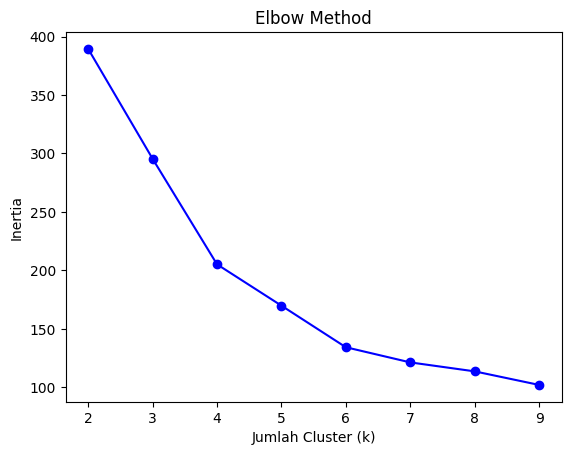

In [ ]:
# Menentukan jumlah cluster optimal dengan Elbow Method
inertia = []
K = range(2,10)
for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(scaled_features)
    inertia.append(kmeans.inertia_)

plt.plot(K, inertia, 'bo-')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()


In [ ]:
# Pilih jumlah cluster optimal (misal k=5)
kmeans = KMeans(n_clusters=5, random_state=42)
df['Cluster'] = kmeans.fit_predict(scaled_features)

In [ ]:
# Menghitung Silhouette Score
silhouette_avg = silhouette_score(scaled_features, df['Cluster'])
print(f"Silhouette Score: {silhouette_avg:.3f}")

# Menilai hasil clustering
if silhouette_avg > 0.7:
    print("Clustering yang sangat baik! Cluster terbentuk dengan sangat baik!")
elif silhouette_avg > 0.5:
    print("Clustering yang cukup baik! Cluster cukup baik!")
else:
    print("Clustering yang lemah. Tapi untuk 6 fitur, ini masih dapat diterima!")

# Membandingkan Silhouette Score untuk berbagai K
print("Perbandingan Silhouette Score untuk berbagai K:")
for k in range(2, 7):
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_temp = kmeans_temp.fit_predict(scaled_features)
    silhouette_temp = silhouette_score(scaled_features, labels_temp)
    print(f"K={k} -> Silhouette Score: {silhouette_temp:.3f}")

Silhouette Score: 0.408
Clustering yang lemah. Tapi untuk 6 fitur, ini masih dapat diterima!
Perbandingan Silhouette Score untuk berbagai K:
K=2 -> Silhouette Score: 0.335
K=3 -> Silhouette Score: 0.358
K=4 -> Silhouette Score: 0.404
K=5 -> Silhouette Score: 0.417
K=6 -> Silhouette Score: 0.428


In [ ]:
# 6. EVALUASI CLUSTER
import plotly.express as px

fig = px.scatter_3d(
    df,
    x='Age',
    y='Annual Income (k$)',
    z='Spending Score (1-100)',
    color='Cluster',
    title='Visualisasi 3D Interaktif Customer Clusters'
)
fig.update_traces(marker=dict(size=6))
fig.show()

In [ ]:
# 7. INTERPRETASI CLUSTER
cluster_summary = df.groupby('Cluster').mean().round(2)
print("\n📋 Rata-rata setiap cluster:")
print(cluster_summary)

print("\n🧠 Interpretasi Sederhana:")
for i, row in cluster_summary.iterrows():
    print(f"\nCluster {i}:")
    print(f"- Rata-rata Usia: {row['Age']}")
    print(f"- Rata-rata Pendapatan: {row['Annual Income (k$)']}")
    print(f"- Rata-rata Spending Score: {row['Spending Score (1-100)']}")


📋 Rata-rata setiap cluster:
         CustomerID  Gender    Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                                       
0             68.78    0.57  55.28               47.62                   41.71
1            161.02    0.55  32.88               86.10                   81.53
2             23.46    0.58  25.77               26.12                   74.85
3             86.38    0.60  26.73               54.31                   40.91
4            166.87    0.48  44.39               89.77                   18.48

🧠 Interpretasi Sederhana:

Cluster 0:
- Rata-rata Usia: 55.28
- Rata-rata Pendapatan: 47.62
- Rata-rata Spending Score: 41.71

Cluster 1:
- Rata-rata Usia: 32.88
- Rata-rata Pendapatan: 86.1
- Rata-rata Spending Score: 81.53

Cluster 2:
- Rata-rata Usia: 25.77
- Rata-rata Pendapatan: 26.12
- Rata-rata Spending Score: 74.85

Cluster 3:
- Rata-rata Usia: 26.73
- Rata-rata Pendapatan: 54.31
- Rata-rata Spending Score

Karakteristik Setiap Cluster (Mean):
               Age  Annual Income (k$)  Spending Score (1-100)
Cluster_2_2                                                   
0            32.07               62.75                   76.67
1            43.01               59.22                   33.98


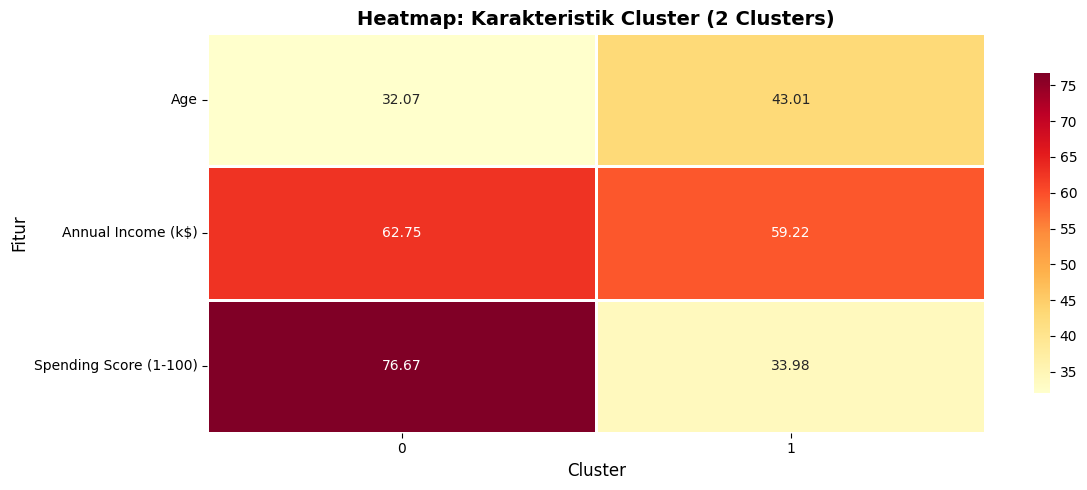

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# --- 1. MEMUAT DATA DAN PRAPROSES (MEMASTIKAN df TERDEFINISI) ---
# Asumsi: Anda sudah mengupload 'Mall_Customers.csv'
try:
    df = pd.read_csv('Mall_Customers.csv')
except FileNotFoundError:
    print("Error: Pastikan 'Mall_Customers.csv' telah diunggah atau path file sudah benar.")
    # Untuk menjalankan di Colab, pastikan file sudah ada di lingkungan
    df = pd.DataFrame()

if not df.empty:

    # --- 2. CLUSTERING (MEMBUAT KOLOM 'Cluster_2_2') ---

    # Memilih fitur untuk clustering (Contoh: Annual Income & Spending Score)
    X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

    # Scaling data
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # Melakukan K-Means dengan 2 Cluster
    n_clusters = 2
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    df['Cluster_2_2'] = kmeans.fit_predict(X_scaled)

    # --- 3. HEATMAP KARAKTERISTIK ---

    # Tentukan fitur yang akan diringkas
    features_to_summarize = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']

    # Hitung mean per cluster dan transpose (ringkasan & transpose digabung)
    cluster_summary_T = df.groupby('Cluster_2_2')[features_to_summarize].mean().round(2).T

    print("Karakteristik Setiap Cluster (Mean):")
    print(cluster_summary_T.T) # Tampilkan data summary sebelum di-transpose

    # Visualisasi Heatmap (subplots dan heatmap digabung)
    plt.figure(figsize=(12, 5)) # Membuat figure dan mengatur ukuran

    sns.heatmap(
        cluster_summary_T,
        annot=True,
        fmt='.2f',
        cmap='YlOrRd',
        cbar_kws={'shrink': 0.8},
        linewidths=1,
        linecolor='white'
    )

    # Pengaturan judul dan label
    plt.title(f'Heatmap: Karakteristik Cluster ({n_clusters} Clusters)', fontsize=14, fontweight='bold')
    plt.ylabel('Fitur', fontsize=12)
    plt.xlabel('Cluster', fontsize=12)

    plt.tight_layout()
    plt.show()

else:
    print("Tidak dapat melanjutkan pembuatan heatmap karena DataFrame 'df' kosong.")